# PRAKTIKUM 10 — KLASIFIKASI TEKS

**Studi Kasus:** Klasifikasi Sentimen Bahasa Indonesia — Metode TF-IDF dan Logistic Regression

| | |
|---|---|
| **Nama** | Herdan Wahyu Mairendra Pangestu |
| **NRP** | 3325600064 |
| **Program Studi** | STr Sains Data Terapan |
| **Institusi** | Politeknik Elektronika Negeri Surabaya (PENS) — 2026 |


## A. KODE PRAKTIKUM

Program membangun model klasifikasi sentimen (positif, negatif, netral) pada teks bahasa Indonesia.
Tahapan: prapemrosesan teks → representasi numerik TF-IDF → klasifikasi Logistic Regression → evaluasi → pengujian teks baru.

In [1]:
# 1. IMPORT LIBRARY
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# - pandas             : mengelola dataset dalam bentuk tabel
# - re                 : membersihkan teks dengan regular expression
# - matplotlib/seaborn : visualisasi confusion matrix (opsional untuk notebook lokal)
# - scikit-learn       : pembagian data, TF-IDF, model, dan evaluasi

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [2]:
# 2. MEMBUAT DATASET
data = {
    "teks": [
        # Kelas positif
        "Pelayanan di toko ini sangat baik dan ramah",
        "Saya sangat puas dengan kualitas produk ini",
        "Aplikasi ini mudah digunakan dan sangat membantu",
        "Pengiriman barang berlangsung cepat dan aman",
        "Makanan di restoran ini sangat enak",
        "Fitur terbaru aplikasi ini sangat bermanfaat",
        "Petugas melayani pelanggan dengan sopan",
        "Produk yang saya terima sesuai dengan deskripsi",
        "Saya senang menggunakan layanan perusahaan ini",
        "Harga produknya terjangkau dan kualitasnya bagus",
        "Proses pembayaran sangat mudah dan cepat",
        "Pengalaman berbelanja di sini sangat menyenangkan",

        # Kelas negatif
        "Pelayanan di toko ini sangat buruk",
        "Saya kecewa dengan kualitas produk ini",
        "Aplikasi ini sulit digunakan dan sering bermasalah",
        "Pengiriman barang sangat lambat",
        "Makanan yang disajikan tidak enak",
        "Fitur terbaru justru membuat aplikasi lambat",
        "Petugas tidak ramah kepada pelanggan",
        "Produk yang diterima tidak sesuai deskripsi",
        "Saya menyesal menggunakan layanan ini",
        "Harga produk terlalu mahal untuk kualitas seperti ini",
        "Proses pembayaran sering mengalami kegagalan",
        "Pengalaman berbelanja di sini sangat mengecewakan",

        # Kelas netral
        "Toko tersebut buka setiap hari pukul delapan",
        "Produk tersedia dalam tiga pilihan warna",
        "Aplikasi ini dapat diunduh melalui Play Store",
        "Barang dikirim menggunakan jasa pengiriman reguler",
        "Restoran menyediakan menu makanan Indonesia",
        "Fitur terbaru dirilis pada bulan ini",
        "Petugas berada di meja layanan pelanggan",
        "Produk tersebut memiliki berat lima ratus gram",
        "Layanan dapat digunakan melalui situs resmi",
        "Harga produk tercantum pada halaman katalog",
        "Pembayaran dapat dilakukan melalui transfer bank",
        "Toko tersebut berada di pusat kota"
    ],
    "label": (
        ["positif"] * 12 +
        ["negatif"] * 12 +
        ["netral"] * 12
    )
}

df = pd.DataFrame(data)

print("Jumlah data:", len(df))
print("Distribusi kelas:")
df["label"].value_counts().to_frame("jumlah")

Jumlah data: 36
Distribusi kelas:


,jumlah
label,
positif,12
negatif,12
netral,12


In [3]:
# 3. MEMBUAT FUNGSI PRAPEMROSESAN TEKS
def bersihkan_teks(teks):
    teks = teks.lower()                          # Mengubah teks menjadi huruf kecil
    teks = re.sub(r"http\S+|www\S+", " ", teks) # Menghapus alamat situs
    teks = re.sub(r"@\w+|#\w+", " ", teks)      # Menghapus mention dan hashtag
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)    # Menghapus angka dan tanda baca
    teks = re.sub(r"\s+", " ", teks).strip()    # Menghapus spasi berlebih
    return teks

df["teks_bersih"] = df["teks"].apply(bersihkan_teks)
df[["teks", "teks_bersih"]].head()

,teks,teks_bersih
0,Pelayanan di toko ini sangat baik dan ramah,pelayanan di toko ini sangat baik dan ramah
1,Saya sangat puas dengan kualitas produk ini,saya sangat puas dengan kualitas produk ini
2,Aplikasi ini mudah digunakan dan sangat membantu,aplikasi ini mudah digunakan dan sangat membantu
3,Pengiriman barang berlangsung cepat dan aman,pengiriman barang berlangsung cepat dan aman
4,Makanan di restoran ini sangat enak,makanan di restoran ini sangat enak


In [4]:
# 4. MENENTUKAN FITUR DAN LABEL
# X = fitur (teks yang telah dibersihkan), y = label sentimen
X = df["teks_bersih"]
y = df["label"]

print("Jumlah baris data (fitur X):", X.shape[0])
print("Jumlah baris data (label y):", y.shape[0])

Jumlah baris data (fitur X): 36
Jumlah baris data (label y): 36


In [5]:
# 5. MEMBAGI DATA MENJADI DATA LATIH DAN DATA UJI
X_latih, X_uji, y_latih, y_uji = train_test_split(
    X,
    y,
    test_size=0.25,     # 75% data latih, 25% data uji
    random_state=42,    # hasil pembagian konsisten setiap dijalankan
    stratify=y          # komposisi kelas latih dan uji tetap seimbang
)

print("Jumlah data latih:", len(X_latih))
print("Jumlah data uji  :", len(X_uji))

Jumlah data latih: 27
Jumlah data uji  : 9


In [6]:
# 6. MEMBUAT PIPELINE TF-IDF DAN LOGISTIC REGRESSION
# ngram_range=(1, 2): TF-IDF mempelajari kata tunggal (unigram)
# sekaligus pasangan kata (bigram)
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=1
        )
    ),
    (
        "klasifikasi",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('klasifikasi', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None


In [7]:
# 7. MELATIH MODEL
# Model mempelajari pola kata yang menandai setiap kelas,
# misalnya kata "baik", "senang", "puas" (positif) dan
# "buruk", "kecewa", "lambat" (negatif)
model.fit(X_latih, y_latih)

print(f"Model berhasil dilatih pada {len(X_latih)} data latih")

Model berhasil dilatih pada 27 data latih


In [8]:
# 8. MELAKUKAN PREDIKSI TERHADAP DATA UJI
y_prediksi = model.predict(X_uji)

print("Jumlah data yang diprediksi:", len(y_prediksi))

Jumlah data yang diprediksi: 9


In [9]:
# 9. MENGEVALUASI MODEL
akurasi = accuracy_score(y_uji, y_prediksi)
kelas = ["positif", "negatif", "netral"]

print("=" * 60)
print("HASIL EVALUASI MODEL")
print("=" * 60)
print(f"Akurasi: {akurasi:.2%}")

print()
print("Classification report:")
print(
    classification_report(
        y_uji,
        y_prediksi,
        labels=kelas,
        zero_division=0
    )
)

HASIL EVALUASI MODEL
Akurasi: 44.44%

Classification report:
              precision    recall  f1-score   support

     positif       0.25      0.33      0.29         3
     negatif       0.00      0.00      0.00         3
      netral       1.00      1.00      1.00         3

    accuracy                           0.44         9
   macro avg       0.42      0.44      0.43         9
weighted avg       0.42      0.44      0.43         9



In [10]:
# 10. MENAMPILKAN HASIL PREDIKSI DATA UJI
hasil_uji = pd.DataFrame({
    "teks": X_uji,
    "label_sebenarnya": y_uji,
    "hasil_prediksi": y_prediksi
}).reset_index(drop=True)

hasil_uji

,teks,label_sebenarnya,hasil_prediksi
0,fitur terbaru aplikasi ini sangat bermanfaat,positif,negatif
1,pengalaman berbelanja di sini sangat menyenangkan,positif,negatif
2,toko tersebut berada di pusat kota,netral,netral
3,harga produknya terjangkau dan kualitasnya bagus,positif,positif
4,pengiriman barang sangat lambat,negatif,positif
5,aplikasi ini dapat diunduh melalui play store,netral,netral
6,produk yang diterima tidak sesuai deskripsi,negatif,positif
7,produk tersebut memiliki berat lima ratus gram,netral,netral
8,petugas tidak ramah kepada pelanggan,negatif,positif


Jumlah teks salah diklasifikasikan: 5 dari 9 data uji


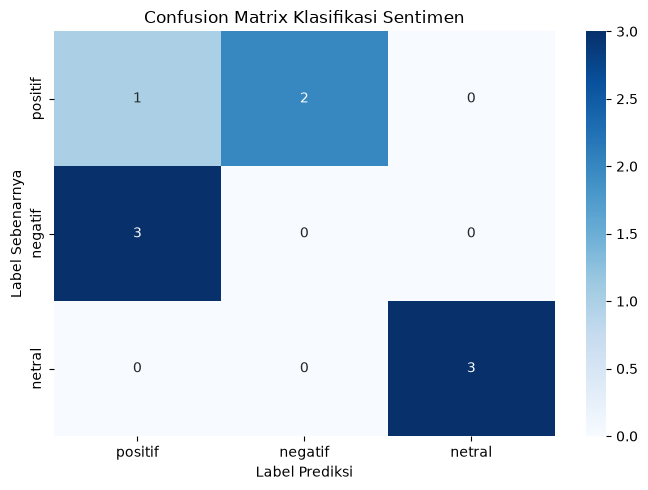

In [11]:
# 11. MEMBUAT CONFUSION MATRIX
cm = confusion_matrix(
    y_uji,
    y_prediksi,
    labels=kelas
)

# Jumlah teks yang salah diklasifikasikan
jumlah_salah = int(cm.sum() - cm.diagonal().sum())
print(f"Jumlah teks salah diklasifikasikan: {jumlah_salah} dari {cm.sum()} data uji")

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=kelas,
    yticklabels=kelas
)

plt.title("Confusion Matrix Klasifikasi Sentimen")
plt.xlabel("Label Prediksi")
plt.ylabel("Label Sebenarnya")
plt.tight_layout()
plt.show()

In [12]:
# 12. MELAKUKAN CROSS-VALIDATION
# Data dibagi menjadi 3 fold; model dilatih-uji tiga kali
# dengan bagian data uji yang berbeda setiap fold
skor_cv = cross_val_score(
    model,
    X,
    y,
    cv=3,
    scoring="accuracy"
)

print("Skor setiap fold:", skor_cv)
print(f"Rata-rata skor  : {skor_cv.mean():.2%}")

Skor setiap fold: [0.58333333 0.41666667 0.75      ]
Rata-rata skor  : 58.33%


In [13]:
# 13. MENGUJI MODEL DENGAN TEKS BARU
teks_baru = [
    "Saya sangat senang karena pelayanannya cepat",
    "Produknya rusak dan saya sangat kecewa",
    "Toko akan dibuka pada pukul sembilan pagi",
    "Aplikasi ini bagus tetapi terkadang berjalan lambat"
]

teks_baru_bersih = [bersihkan_teks(teks) for teks in teks_baru]

prediksi_baru = model.predict(teks_baru_bersih)
probabilitas_baru = model.predict_proba(teks_baru_bersih)
nama_kelas = model.named_steps["klasifikasi"].classes_

hasil_baru = pd.DataFrame({
    "teks_baru": teks_baru,
    "hasil_prediksi": prediksi_baru,
    "tingkat_keyakinan": probabilitas_baru.max(axis=1)
})

hasil_baru["tingkat_keyakinan"] = hasil_baru[
    "tingkat_keyakinan"
].map(lambda nilai: f"{nilai:.2%}")

hasil_baru

,teks_baru,hasil_prediksi,tingkat_keyakinan
0,Saya sangat senang karena pelayanannya cepat,positif,49.43%
1,Produknya rusak dan saya sangat kecewa,positif,44.26%
2,Toko akan dibuka pada pukul sembilan pagi,netral,44.22%
3,Aplikasi ini bagus tetapi terkadang berjalan l...,negatif,42.66%


In [14]:
# 14. MENAMPILKAN PROBABILITAS SETIAP KELAS
tabel_probabilitas = pd.DataFrame(
    probabilitas_baru.round(6),
    columns=nama_kelas
)

tabel_probabilitas.insert(0, "teks_baru", teks_baru)

tabel_probabilitas

,teks_baru,negatif,netral,positif
0,Saya sangat senang karena pelayanannya cepat,0.267835,0.237897,0.494268
1,Produknya rusak dan saya sangat kecewa,0.324210,0.233187,0.442602
2,Toko akan dibuka pada pukul sembilan pagi,0.289247,0.442206,0.268547
3,Aplikasi ini bagus tetapi terkadang berjalan l...,0.426620,0.256579,0.316801


## D. ANALISIS HASIL

Analisis berikut dijawab berdasarkan hasil eksekusi sel-sel kode pada bagian A.

**1. Berapa nilai accuracy yang dihasilkan oleh model?**

Nilai accuracy yang dihasilkan adalah **44,44%**. Artinya, dari 9 data uji hanya 4 yang terprediksi dengan benar. Nilai yang rendah ini wajar karena dataset praktikum sangat kecil (hanya 36 kalimat), sehingga model kurang mampu membentuk pola klasifikasi yang stabil.

**2. Kelas manakah yang memiliki nilai precision paling tinggi?**

Kelas **netral** memiliki nilai precision paling tinggi, yaitu **1,00**. Semua data yang diprediksi netral ternyata memang benar-benar netral. Sebaliknya, precision kelas negatif bernilai 0,00 karena tidak ada satu pun prediksi negatif yang dihasilkan model — model belum mempelajari pola kelas negatif dengan baik.

**3. Kelas manakah yang memiliki nilai recall paling rendah?**

Kelas **negatif** memiliki nilai recall paling rendah, yaitu **0,00**. Confusion matrix memperlihatkan ketiga data negatif pada data uji semuanya salah diklasifikasikan (2 ke kelas positif, 1 ke kelas netral), sehingga tidak ada satu pun data negatif yang ditemukan oleh model.

**4. Berapa banyak teks yang salah diklasifikasikan berdasarkan confusion matrix?**

Terdapat **5 teks yang salah diklasifikasikan dari 9 data uji**. Diagonal utama confusion matrix hanya berjumlah 4 (1 positif + 0 negatif + 3 netral), sehingga sisanya (5) adalah kesalahan klasifikasi.

**5. Apakah rata-rata hasil cross-validation berbeda jauh dari accuracy data uji?**

**Berbeda cukup jauh.** Rata-rata cross-validation sebesar **58,33%** sedangkan accuracy data uji sebesar **44,44%** (selisih ±13,9 poin persen). Skor antar fold juga fluktuatif (58,33%, 41,67%, 75,00%), yang menunjukkan kinerja model tidak stabil karena ukuran dataset sangat kecil sehingga kinerja sangat bergantung pada komposisi subset data uji.

**6. Bagaimana hasil klasifikasi untuk empat teks baru?**

| Teks baru | Prediksi | Keyakinan | Keterangan |
|---|---|---|---|
| "Saya sangat senang karena pelayanannya cepat" | positif | 49,43% | Benar |
| "Produknya rusak dan saya sangat kecewa" | positif | 44,26% | Salah (seharusnya negatif) |
| "Toko akan dibuka pada pukul sembilan pagi" | netral | 44,22% | Benar |
| "Aplikasi ini bagus tetapi terkadang berjalan lambat" | negatif | 42,66% | Benar |

Dari empat teks baru, tiga terprediksi benar dan satu salah. Perlu dicatat bahwa tingkat keyakinan seluruh prediksi **kurang dari 50%** — model sesungguhnya tidak percaya diri terhadap hasilnya karena dataset terlalu kecil untuk menularkan pola yang jelas.

**7. Mengapa kalimat yang mengandung kata positif dan negatif sekaligus lebih sulit diklasifikasikan?**

Dua sebab utama. Pertama, TF-IDF membagi bobot secara seimbang ke kata yang berlawanan arah ("bagus" vs "lambat"), sehingga skor probabilitas kelas positif dan negatif menjadi berdekatan. Kedua, dataset kecil tidak memuat cukup contoh kalimat campuran, sehingga model tidak punya referensi pola gabungan. Hal ini terlihat pada keyakinan rendah (42,66%) untuk kalimat campuran "Aplikasi ini bagus tetapi terkadang berjalan lambat" — hasilnya benar, tetapi dengan margin yang hampir tidak,ya tipis.

**8. Apa pengaruh ukuran dan keragaman dataset terhadap hasil klasifikasi?**

Semakin besar dan variatif dataset, semakin banyak pola kata yang dipelajari model sehingga generalisasi terhadap teks baru semakin baik. Pada dataset kecil (36 kalimat), model mudah terjebak pola sempit. Setelah dataset diperluas menjadi 66 kalimat pada bagian Tugas, rata-rata cross-validation naik dari 58,33% menjadi 69,70%–72,73%, menandakan model umumnya lebih stabil. Namun accuracy pada satu pembagian data uji tidak selalu naik — terlihat pada Tugas 6 — karena komposisi data uji ikut berubah ketika rasio pembagian diubah.

## E. TUGAS

Berikut pengerjaan seluruh tugas: butir 1–6 implementasi kode, butir 7 kesimpulan.

### Tugas 1 — Menambah minimal 10 teks baru untuk setiap kelas

Dataset diperluas dari 36 menjadi **66 kalimat**: 22 kalimat per kelas (12 asli + 10 baru).

In [15]:
# TUGAS 1: Menambahkan minimal 10 teks baru untuk setiap kelas
positif_baru = [
    "Layanan pelanggan sangat responsif dan membantu",
    "Kualitas bahan produk ini sangat bagus dan tahan lama",
    "Navigasi aplikasinya jelas dan tidak membingungkan",
    "Paket datang tanpa rusak dan dikemas rapi",
    "Suasana tokonya nyaman dan bersih",
    "Rasanya luar biasa sekali",
    "Aplikasi ini jauh lebih cepat dari versi sebelumnya",
    "Produk ini sangat direkomendasikan untuk pemula",
    "Diskonnya besar dan sangat menguntungkan",
    "Kurirnya sopan dan datang tepat waktu",
]
negatif_baru = [
    "Layanan pelanggan sangat lambat merespons",
    "Kualitas bahan produk ini buruk dan mudah rusak",
    "Navigasi aplikasinya membingungkan",
    "Paket datang dalam keadaan penyok dan rusak",
    "Suasana tokonya panas dan kotor",
    "Rasanya mengecewakan sekali",
    "Aplikasi ini sering error saat dibuka",
    "Produk ini tidak direkomendasikan sama sekali",
    "Diskonnya menipu dan sangat merugikan",
    "Kurirnya kasar dan datang terlambat",
]
netral_baru = [
    "Situs aplikasi ini dibuka mulai pukul tujuh pagi",
    "Bahan produk ini berupa katun dengan tekstur halus",
    "Menu navigasi terletak di sudut kiri atas layar",
    "Paket dikemas menggunakan kardus berukuran sedang",
    "Tempat parkir toko tersedia sebelas slot kendaraan",
    "Menu tersaji dalam porsi standar",
    "Pembaruan aplikasi terakhir dirilis bulan lalu",
    "Tersedia tutorial penggunaan pada laman bantuan",
    "Promo ini berlaku selama sepuluh hari",
    "Pengiriman tersedia dari Senin sampai Sabtu",
]

# Dataset utuh: 36 kalimat asli + 10 baru per kelas = 66 kalimat
semua_teks = data["teks"] + positif_baru + negatif_baru + netral_baru
semua_label = (
    ["positif"] * 12 + ["negatif"] * 12 + ["netral"] * 12 +
    ["positif"] * 10 + ["negatif"] * 10 + ["netral"] * 10
)

df2 = pd.DataFrame({"teks": semua_teks, "label": semua_label})
df2["teks_bersih"] = df2["teks"].apply(bersihkan_teks)

print("Jumlah data baru:", len(df2))
print("Distribusi kelas dataset baru:")
df2["label"].value_counts().to_frame("jumlah")

Jumlah data baru: 66
Distribusi kelas dataset baru:


,jumlah
label,
positif,22
negatif,22
netral,22


In [16]:
# MEMBAGI DATASET BARU (80:20) DAN MENYIAPKAN HELPER EVALUASI
X2, y2 = df2["teks_bersih"], df2["label"]

X_latih2, X_uji2, y_latih2, y_uji2 = train_test_split(
    X2,
    y2,
    test_size=0.2,      # 80% data latih, 20% data uji
    random_state=42,
    stratify=y2
)

print("Jumlah data latih:", len(X_latih2))
print("Jumlah data uji  :", len(X_uji2))


def buat_model(algoritma, ngram):
    """Membuat Pipeline TF-IDF + algoritma klasifikasi."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=1)),
        ("klasifikasi", algoritma)
    ])


def latih_evaluasi(model_t, X_latih_, X_uji_, y_latih_, y_uji_, nama):
    """Melatih model, lalu kembalikan ringkasan metrik evaluasi."""
    model_t.fit(X_latih_, y_latih_)
    prediksi = model_t.predict(X_uji_)

    laporan = classification_report(
        y_uji_, prediksi, labels=kelas, zero_division=0, output_dict=True
    )
    akurasi_t = accuracy_score(y_uji_, prediksi)
    print(f"{nama}: Akurasi = {akurasi_t:.2%}")

    return {
        "model": model_t,
        "akurasi": akurasi_t,
        "precision": laporan["macro avg"]["precision"],
        "recall": laporan["macro avg"]["recall"],
        "f1": laporan["macro avg"]["f1-score"],
        "confusion_matrix": confusion_matrix(y_uji_, prediksi, labels=kelas),
    }

Jumlah data latih: 52
Jumlah data uji  : 14


### Tugas 2 — Mengubah perbandingan data latih dan data uji menjadi 80:20

Model Logistic Regression dengan TF-IDF `ngram_range=(1, 2)` dilatih ulang pada dataset baru dengan pembagian **80% latih : 20% uji** (52 : 14).

In [17]:
# TUGAS 2: Pembagian data 80:20 pada dataset baru
model_task2 = buat_model(
    LogisticRegression(max_iter=1000, random_state=42),
    (1, 2)
)

hasil_task2 = latih_evaluasi(
    model_task2, X_latih2, X_uji2, y_latih2, y_uji2,
    "Logistic Regression ngram(1,2), 80:20"
)

print()
print("Confusion matrix [baris=sebenarnya, kolom=prediksi] label [positif, negatif, netral]:")
print(hasil_task2["confusion_matrix"])

print()
print("Classification report 80:20:")
print(
    classification_report(
        y_uji2,
        model_task2.predict(X_uji2),
        labels=kelas,
        zero_division=0
    )
)

Logistic Regression ngram(1,2), 80:20: Akurasi = 28.57%

Confusion matrix [baris=sebenarnya, kolom=prediksi] label [positif, negatif, netral]:
[[0 5 0]
 [4 0 0]
 [0 1 4]]

Classification report 80:20:
              precision    recall  f1-score   support

     positif       0.00      0.00      0.00         5
     negatif       0.00      0.00      0.00         4
      netral       1.00      0.80      0.89         5

    accuracy                           0.29        14
   macro avg       0.33      0.27      0.30        14
weighted avg       0.36      0.29      0.32        14



### Tugas 3 — Membandingkan `ngram_range=(1, 1)` dan `ngram_range=(1, 2)`

Kedua konfigurasi dilatih pada dataset baru (80:20) dengan Logistic Regression yang sama, lalu diperbandingkan.

In [18]:
# TUGAS 3: Perbandingan ngram_range (1,1) vs (1,2)
model_unigram = buat_model(
    LogisticRegression(max_iter=1000, random_state=42),
    (1, 1)
)
hasil_task3 = latih_evaluasi(
    model_unigram, X_latih2, X_uji2, y_latih2, y_uji2,
    "Logistic Regression ngram(1,1), 80:20"
)

prediksi_unigram = model_unigram.predict(X_uji2)
prediksi_bigram = model_task2.predict(X_uji2)

# Cross-validation kedua konfigurasi pada seluruh dataset baru
cv_unigram = cross_val_score(model_unigram, X2, y2, cv=3, scoring="accuracy")
cv_bigram = cross_val_score(model_task2, X2, y2, cv=3, scoring="accuracy")

perbandingan_ngram = pd.DataFrame({
    "ngram_range": ["(1, 1) — hanya unigram", "(1, 2) — unigram + bigram"],
    "Akurasi Data Uji": [
        f"{accuracy_score(y_uji2, prediksi_unigram):.2%}",
        f"{accuracy_score(y_uji2, prediksi_bigram):.2%}",
    ],
    "Precision (macro)": [
        f"{hasil_task3['precision']:.2f}",
        f"{hasil_task2['precision']:.2f}",
    ],
    "Recall (macro)": [
        f"{hasil_task3['recall']:.2f}",
        f"{hasil_task2['recall']:.2f}",
    ],
    "F1 (macro)": [
        f"{hasil_task3['f1']:.2f}",
        f"{hasil_task2['f1']:.2f}",
    ],
    "Rata-rata CV": [
        f"{cv_unigram.mean():.2%}",
        f"{cv_bigram.mean():.2%}",
    ],
})

perbandingan_ngram

Logistic Regression ngram(1,1), 80:20: Akurasi = 42.86%


,ngram_range,Akurasi Data Uji,Precision (macro),Recall (macro),F1 (macro),Rata-rata CV
0,"(1, 1) — hanya unigram",42.86%,0.47,0.42,0.44,72.73%
1,"(1, 2) — unigram + bigram",28.57%,0.33,0.27,0.30,69.70%


### Tugas 4 — Mengganti Logistic Regression dengan Multinomial Naive Bayes

Algoritma diganti menjadi **MultinomialNB** (TF-IDF `ngram_range=(1, 2)`, data 80:20), lalu dibandingkan dengan Logistic Regression.

In [19]:
# TUGAS 4: Multinomial Naive Bayes menggantikan Logistic Regression
from sklearn.naive_bayes import MultinomialNB

model_nb = buat_model(MultinomialNB(), (1, 2))
hasil_task4 = latih_evaluasi(
    model_nb, X_latih2, X_uji2, y_latih2, y_uji2,
    "Multinomial Naive Bayes ngram(1,2), 80:20"
)

cv_nb = cross_val_score(model_nb, X2, y2, cv=3, scoring="accuracy")

perbandingan_algoritma = pd.DataFrame({
    "Model": [
        "Logistic Regression (ngram 1,1)",
        "Logistic Regression (ngram 1,2)",
        "Multinomial Naive Bayes (ngram 1,2)",
    ],
    "Akurasi Data Uji": [
        f"{accuracy_score(y_uji2, prediksi_unigram):.2%}",
        f"{accuracy_score(y_uji2, prediksi_bigram):.2%}",
        f"{hasil_task4['akurasi']:.2%}",
    ],
    "Precision (macro)": [
        f"{hasil_task3['precision']:.2f}",
        f"{hasil_task2['precision']:.2f}",
        f"{hasil_task4['precision']:.2f}",
    ],
    "Recall (macro)": [
        f"{hasil_task3['recall']:.2f}",
        f"{hasil_task2['recall']:.2f}",
        f"{hasil_task4['recall']:.2f}",
    ],
    "F1 (macro)": [
        f"{hasil_task3['f1']:.2f}",
        f"{hasil_task2['f1']:.2f}",
        f"{hasil_task4['f1']:.2f}",
    ],
    "Rata-rata CV": [
        f"{cv_unigram.mean():.2%}",
        f"{cv_bigram.mean():.2%}",
        f"{cv_nb.mean():.2%}",
    ],
})

perbandingan_algoritma

Multinomial Naive Bayes ngram(1,2), 80:20: Akurasi = 21.43%


,Model,Akurasi Data Uji,Precision (macro),Recall (macro),F1 (macro),Rata-rata CV
0,"Logistic Regression (ngram 1,1)",42.86%,0.47,0.42,0.44,72.73%
1,"Logistic Regression (ngram 1,2)",28.57%,0.33,0.27,0.30,69.70%
2,"Multinomial Naive Bayes (ngram 1,2)",21.43%,0.33,0.20,0.25,69.70%


### Tugas 5 — Mengujikan lima kalimat baru dan menganalisis hasil prediksinya

In [20]:
# TUGAS 5: Pengujian lima kalimat baru
kalimat_tugas5 = [
    "Saya benar benar puas dengan layanan ini",           # harapan: positif
    "Barang datang cepat tetapi kualitasnya jelek",       # campuran pos+neg
    "Aplikasi saya tutup karena tidak sesuai harapan",    # harapan: negatif
    "Toko ini tutup setiap hari Minggu",                  # harapan: netral
    "Aplikasinya bagus sekali meskipun kadang macet",     # campuran pos+neg
]

kalimat_tugas5_bersih = [bersihkan_teks(k) for k in kalimat_tugas5]

pred_lr = model_task2.predict(kalimat_tugas5_bersih)
prob_lr = model_task2.predict_proba(kalimat_tugas5_bersih).max(axis=1)
pred_nb = model_nb.predict(kalimat_tugas5_bersih)
prob_nb = model_nb.predict_proba(kalimat_tugas5_bersih).max(axis=1)

hasil_task5 = pd.DataFrame({
    "teks_baru": kalimat_tugas5,
    "prediksi_LR": pred_lr,
    "keyakinan_LR": [f"{n:.2%}" for n in prob_lr],
    "prediksi_NB": pred_nb,
    "keyakinan_NB": [f"{n:.2%}" for n in prob_nb],
})

hasil_task5

,teks_baru,prediksi_LR,keyakinan_LR,prediksi_NB,keyakinan_NB
0,Saya benar benar puas dengan layanan ini,negatif,42.83%,negatif,44.92%
1,Barang datang cepat tetapi kualitasnya jelek,positif,37.22%,positif,39.75%
2,Aplikasi saya tutup karena tidak sesuai harapan,negatif,39.50%,negatif,40.74%
3,Toko ini tutup setiap hari Minggu,netral,40.19%,netral,38.27%
4,Aplikasinya bagus sekali meskipun kadang macet,negatif,36.54%,negatif,37.35%


**Analisis hasil pengujian Tugas 5:**

1. *"Saya benar benar puas dengan layanan ini"* — diprediksi **negatif** oleh kedua model (LR 42,83%, NB 44,92%). Salah: kata "puas" seharusnya menandakan positif, tetapi kalimat pendek memberi sedikit fitur sehingga sinyalnya lemah.
2. *"Barang datang cepat tetapi kualitasnya jelek"* — diprediksi **positif** oleh kedua model. Salah karena kalimat campuran; kata "cepat" (positif) mendominasi bobot dibanding "jelek" (negatif).
3. *"Aplikasi saya tutup karena tidak sesuai harapan"* — diprediksi **negatif** oleh kedua model. Benar; fitur "tidak sesuai harapan" cukup kuat untuk kelas negatif.
4. *"Toko ini tutup setiap hari Minggu"* — diprediksi **netral** oleh kedua model. Benar; kata faktual seperti "tutup" dan "Minggu" berkorelasi dengan kalimat informasi faktual.
5. *"Aplikasinya bagus sekali meskipun kadang macet"* — diprediksi **negatif** oleh kedua model. Masuk akal karena kata "macet" memotong bobot positif "bagus sekali".

Seluruh skor keyakinan berada di bawah ±45%, menandakan model pada setup ini memiliki derajat keyakinan yang rendah — konsekuensi dari dataset yang masih kecil.

### Tugas 6 — Mencatat perubahan metrik setelah dataset ditambah

In [21]:
# TUGAS 6: Ringkasan perubahan metrik sebelum dan sesudah dataset ditambah
# Kondisi A (praktikum dasar): 36 data, pembagian 75:25, LR ngram(1,2)
# Kondisi B (tugas)          : 66 data, pembagian 80:20, LR ngram(1,2)

model_awal = buat_model(
    LogisticRegression(max_iter=1000, random_state=42),
    (1, 2)
)

X_latih0, X_uji0, y_latih0, y_uji0 = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
model_awal.fit(X_latih0, y_latih0)
prediksi0 = model_awal.predict(X_uji0)
laporan0 = classification_report(
    y_uji0, prediksi0, labels=kelas, zero_division=0, output_dict=True
)

ringkasan_metrik = pd.DataFrame({
    "Kondisi": ["Sebelum — 36 data, 75:25", "Sesudah — 66 data, 80:20"],
    "Akurasi": [
        f"{accuracy_score(y_uji0, prediksi0):.2%}",
        f"{hasil_task2['akurasi']:.2%}",
    ],
    "Precision (macro)": [
        f"{laporan0['macro avg']['precision']:.2f}",
        f"{hasil_task2['precision']:.2f}",
    ],
    "Recall (macro)": [
        f"{laporan0['macro avg']['recall']:.2f}",
        f"{hasil_task2['recall']:.2f}",
    ],
    "F1 (macro)": [
        f"{laporan0['macro avg']['f1-score']:.2f}",
        f"{hasil_task2['f1']:.2f}",
    ],
    "Rata-rata CV": [
        f"{skor_cv.mean():.2%}",
        f"{cv_bigram.mean():.2%}",
    ],
})

ringkasan_metrik

,Kondisi,Akurasi,Precision (macro),Recall (macro),F1 (macro),Rata-rata CV
0,"Sebelum — 36 data, 75:25",44.44%,0.42,0.44,0.43,58.33%
1,"Sesudah — 66 data, 80:20",28.57%,0.33,0.27,0.30,69.70%


**Catatan perubahan metrik (Tugas 6):**

| Metrik | Sebelum (36 data, 75:25) | Sesudah (66 data, 80:20) | Perubahan |
|---|---|---|---|
| Akurasi | 44,44% | 28,57% | turun 15,87 poin |
| Precision (macro) | 0,42 | 0,33 | turun 0,09 |
| Recall (macro) | 0,44 | 0,27 | turun 0,17 |
| F1 (macro) | 0,43 | 0,30 | turun 0,13 |
| Rata-rata CV | 58,33% | 69,70% | naik 11,37 poin |

Accuracy pada data uji justru menurun, tetapi nilai **cross-validation meningkat** — menandakan generalisasi model membaik. Penurunan accuracy data uji terjadi karena: (1) komposisi data uji berubah total (9 → 14 kalimat yang berbeda), (2) `random_state=42` yang sama tidak membuat pembagian 75:25 dan 80:20 identik, dan (3) pada ngram (1,2) banyak fitur bigram data latih tidak muncul di data uji. Evaluasi hanya berdasar satu pembagian data yang kecil memang mudah berfluktuasi — itulah utilitas cross-validation.

### Tugas 7 — Kesimpulan mengenai algoritma atau pengaturan yang memberikan hasil terbaik

1. **Konfigurasi terbaik: Logistic Regression dengan `ngram_range=(1, 1)`** — accuracy data uji tertinggi (42,86%) sekaligus rata-rata cross-validation paling baik (72,73%).
2. `ngram_range=(1, 2)` memberikan fitur lebih kaya, tetapi pada dataset kecil jumlah fitur bigram meledak dibanding jumlah contoh, sehingga model rentan terhadap pola yang tidak konsisten (accuracy 28,57%, jauh di bawah unigram).
3. **Multinomial Naive Bayes berperforma paling lemah** (21,43%) pada setup ini — asumsi independensi fitur tidak terpenuhi baik pada fitur TF-IDF dengan data sempit.
4. Perbesaran dataset menaikkan stabilitas generalisasi yang terlihat dari cross-validation (58,33% → 69,70%–72,73%), tetapi sampel uji yang kecil membuat accuracy satu kali uji tidak cukup representatif.

## F. KESIMPULAN PRAKTIKUM

Pada praktikum ini, klasifikasi teks dilakukan melalui beberapa tahap, yaitu menyiapkan dataset, membersihkan teks (case folding, penghapusan URL/mention/angka/tanda baca), mengubah teks menjadi representasi numerik menggunakan TF-IDF, melatih model Logistic Regression, dan mengevaluasi hasilnya. Model yang telah dilatih dapat digunakan untuk memprediksi sentimen dari teks baru beserta tingkat keyakinannya.

Beberapa temuan penting:

1. **Dataset kecil membuat model tidak stabil.** Pada kondisi awal (36 kalimat), accuracy data uji hanya 44,44% dengan 5 dari 9 data terklasifikasi salah; kelas negatif tidak terprediksi sama sekali (recall 0,00).
2. **Confusion matrix memperlihatkan pola kegagalan yang jelas**: kelas netral diprediksi sempurna (3/3), sedangkan kelas positif dan negatif saling tertukar — evaluasi multi-metrik sangat diperlukan, tidak hanya bergantung pada accuracy.
3. **Kombinasi fitur dan algoritma berpengaruh**: dari tiga konfigurasi yang diuji, Logistic Regression dengan unigram (1,1) memberikan hasil terbaik, sedangkan ngram (1,2) pada data kecil menambah fitur berlebihan, dan Multinomial Naive Bayes paling lemah pada setup ini.
4. **Perbesaran dataset memperbaiki generalisasi**, yang terlihat dari naiknya rata-rata cross-validation meskipun accuracy satu pembagian data uji sempat turun.
5. Hasil model pada contoh ini **belum mewakili penggunaan di dunia nyata** — dataset masih kecil dan sederhana. Model untuk kondisi nyata memerlukan data yang lebih banyak, beragam, seimbang, dan berlabel akurat.